# Notebook 6 - Multivariate Analysis
Sprint 4 - EDA

Multivariate analysis studies the relationships among more than two variables at the same time. Here I look at the correlation matrix, the heatmap, the pair plot, feature interactions and multicollinearity. I want to know which features move together, which are related to Churn, and which carry the same information. As before, a correlation is an observation and not proof of cause.

**Dataset:** Telco Customer Churn (Kaggle, 7043 rows and 21 columns)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# working copy for analysis only
df_eda = df.copy()
df_eda["TotalCharges"] = pd.to_numeric(df_eda["TotalCharges"], errors="coerce")
df_eda["Churn_num"] = (df_eda["Churn"] == "Yes").astype(int)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
print("Ready")

Ready


## Preparing an encoded copy for correlation

Correlation needs numbers, but most of my columns are text. For this notebook only, I make an encoded copy: two category columns become 0 and 1, and the other categorical columns become separate 0 and 1 columns (one for each category, which is one-hot encoding). This is only for studying relationships. The real encoding will be done in the preprocessing sprint.

In [2]:
df_enc = df_eda.drop(columns=["customerID", "Churn"]).copy()

# columns with exactly two categories become 0 and 1
for col in df_enc.columns:
    if df_enc[col].dtype != "int64" and df_enc[col].dtype != "float64":
        if df_enc[col].nunique() == 2:
            first_label = sorted(df_enc[col].unique())[-1]     # Yes or Male gets 1
            df_enc[col] = (df_enc[col] == first_label).astype(int)

# remaining categorical columns become one column per category
df_enc = pd.get_dummies(df_enc, dtype=int)

print("Encoded shape:", df_enc.shape)
print(df_enc.columns.tolist())

Encoded shape: (7043, 41)
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn_num', 'MultipleLines_No', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mail

The encoded copy has many more columns than the original. Binary columns such as Partner are now 0 and 1 with Yes as 1, and gender has Male as 1. Columns like Contract are split into Contract_Month-to-month, Contract_One year and Contract_Two year.

## 1. Correlation Matrix

**Concept:** A correlation matrix is a table that shows the correlation coefficient between every pair of variables. Each value is between -1 and +1. A value near +1 is a strong positive relationship, near -1 is a strong negative relationship and near 0 is a weak or no straight line relationship. For two 0 and 1 columns the Pearson value is also a valid measure of association.

**Example (business):** A retailer studies price, advertising, discount and sales together. The matrix shows at once that sales rise with advertising, fall with price, and that price and discount are related to each other, which a pair by pair look could easily miss.

In [3]:
corr_num = df_eda[num_cols + ["Churn_num"]].corr()
corr_num.round(2)

,tenure,MonthlyCharges,TotalCharges,Churn_num
tenure,1.00,0.25,0.83,-0.35
MonthlyCharges,0.25,1.00,0.65,0.19
TotalCharges,0.83,0.65,1.00,-0.20
Churn_num,-0.35,0.19,-0.20,1.00


**What the code does:** It calculates the correlation of every pair among the three numerical features and the numeric Churn column and displays it as a table.

**Why this method was used:** The matrix compares all pairs in one place, so I can see the whole structure of the numerical features instead of checking pairs one by one.

**What the output means:** Tenure and TotalCharges have a strong positive correlation of about 0.83. MonthlyCharges and TotalCharges have about 0.65. Tenure and MonthlyCharges have about 0.25. With Churn, tenure is about -0.35, TotalCharges about -0.20 and MonthlyCharges about +0.19.

**Insights:** The three numerical features overlap, mainly because TotalCharges is built from tenure and MonthlyCharges. Tenure is the numerical feature most related to Churn, and it is a negative relationship, so longer tenure goes with less churn.

**Effect on the ML pipeline:** Features that are highly correlated with each other add little new information, and can make linear model coefficients unstable. The matrix is the first step in deciding which features to keep, combine or drop.

## 2. Heatmap

**Concept:** A heatmap draws the correlation matrix as a grid of colored cells, so strong positive and negative relationships can be seen by color instead of reading numbers. Using a diverging color scale centered at 0 makes the sign visible.

**Example (AI/ML):** A data scientist with 40 features cannot read a 40 by 40 table of numbers, but on a heatmap the blocks of strong red or blue show at a glance which groups of features move together.

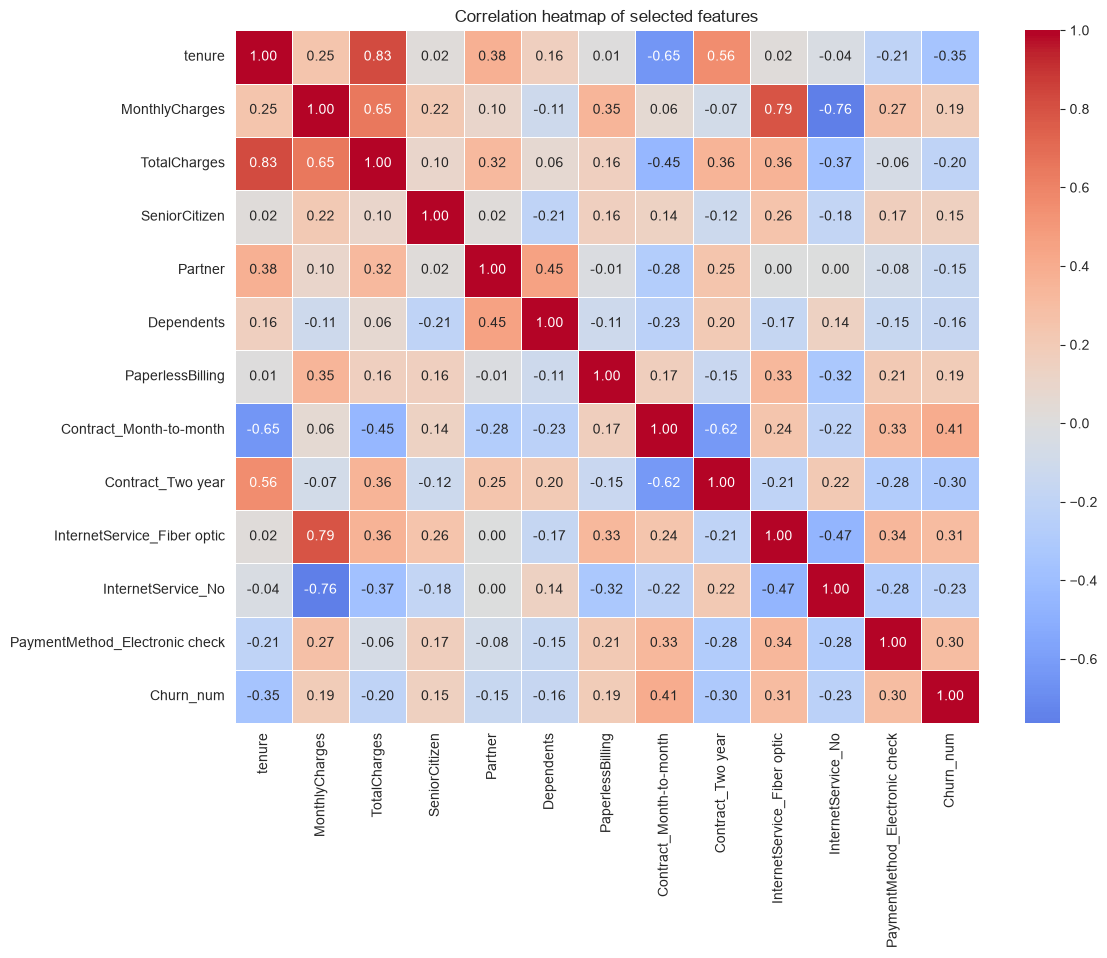

In [4]:
selected = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "Partner", "Dependents",
            "PaperlessBilling", "Contract_Month-to-month", "Contract_Two year",
            "InternetService_Fiber optic", "InternetService_No",
            "PaymentMethod_Electronic check", "Churn_num"]

plt.figure(figsize=(12, 9))
sns.heatmap(df_enc[selected].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation heatmap of selected features")
plt.show()

**What the code does:** It draws a heatmap with the correlation values written in each cell. I selected thirteen important columns, because a heatmap of all the encoded columns would be too crowded to read. The colors go from blue (negative) through white (zero) to red (positive).

**Why this method was used:** A heatmap is the standard plot for a correlation matrix, and the diverging color scale with the center at 0 makes it clear whether a relationship is positive or negative.

**What the output means:** The strongest red cells are between tenure and TotalCharges, between MonthlyCharges and fiber optic internet, and between tenure and the two year contract. The strongest blue cells are between tenure and the month-to-month contract, between MonthlyCharges and no internet, and between month-to-month and two year contracts. In the Churn_num row the strongest red cells are month-to-month contract, fiber optic and electronic check, and the strongest blue cells are tenure and two year contract.

**Insights:** Customers on long contracts have long tenure, and customers on fiber optic pay high monthly charges. Month-to-month customers, fiber customers and electronic check users are the most linked with churn. Partner and Dependents are related to each other, and also related to lower churn, but the link is weaker.

**Effect on the ML pipeline:** Several features describe the same behavior, for example tenure, contract type and TotalCharges. The model will not need all of them, and the heatmap helps to choose a smaller set of features.

## 3. Strong, Weak and Negative Correlations with the Target

**Concept:** Sorting all features by their correlation with the target shows which ones are most associated with it. Features with a high absolute value are strong candidates for a model, and features near 0 are weak. The sign shows the direction.

**Example (business):** In a house price dataset, area has a correlation of 0.7 with price and the year of the last paint job has 0.02. The first is a strong feature and the second is probably useless.

In [5]:
target_corr = df_enc.corr()["Churn_num"].drop("Churn_num").sort_values()

print("Strongest negative (less churn):")
print(target_corr.head(8).round(2).to_string())
print()
print("Strongest positive (more churn):")
print(target_corr.tail(8).sort_values(ascending=False).round(2).to_string())
print()
print("Weakest (closest to zero):")
print(target_corr.abs().sort_values().head(8).round(3).to_string())

Strongest negative (less churn):
tenure                                 -0.35
Contract_Two year                      -0.30
StreamingMovies_No internet service    -0.23
InternetService_No                     -0.23
TechSupport_No internet service        -0.23
DeviceProtection_No internet service   -0.23
OnlineBackup_No internet service       -0.23
StreamingTV_No internet service        -0.23

Strongest positive (more churn):
Contract_Month-to-month           0.41
OnlineSecurity_No                 0.34
TechSupport_No                    0.34
InternetService_Fiber optic       0.31
PaymentMethod_Electronic check    0.30
OnlineBackup_No                   0.27
DeviceProtection_No               0.25
MonthlyCharges                    0.19

Weakest (closest to zero):
gender                            0.009
PhoneService                      0.012
MultipleLines_No phone service    0.012
MultipleLines_No                  0.033
MultipleLines_Yes                 0.040
StreamingMovies_Yes              

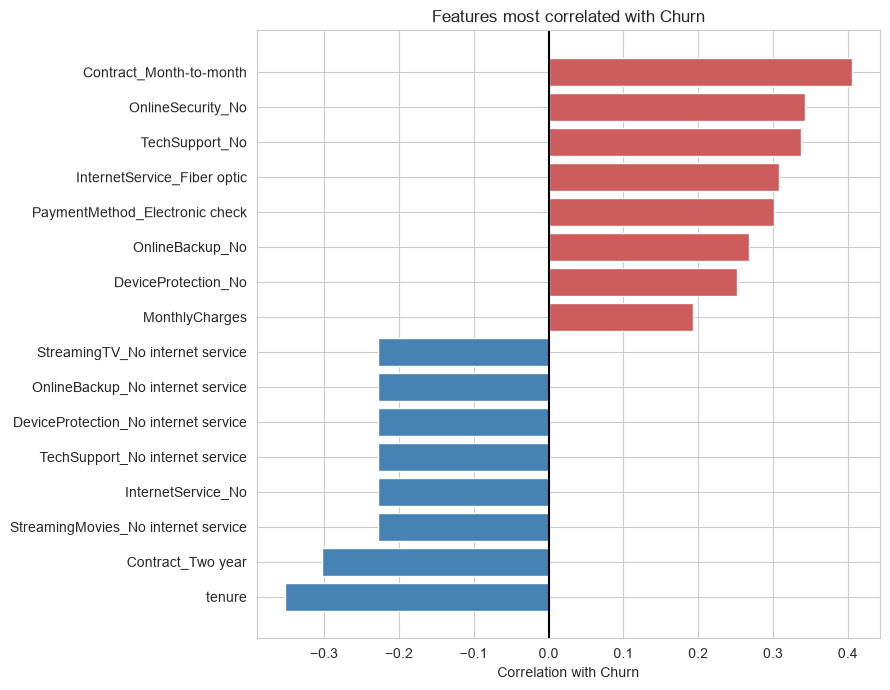

In [6]:
top = pd.concat([target_corr.head(8), target_corr.tail(8)])

plt.figure(figsize=(9, 7))
colors = ["steelblue" if v < 0 else "indianred" for v in top.values]
plt.barh(top.index, top.values, color=colors)
plt.axvline(0, color="black")
plt.title("Features most correlated with Churn")
plt.xlabel("Correlation with Churn")
plt.tight_layout()
plt.show()

**What the code does:** The first cell takes the correlation of every encoded feature with Churn, sorts it, and prints the eight most negative, the eight most positive and the eight closest to zero. The second cell draws the sixteen strongest as a bar chart, with red for positive and blue for negative.

**Why this method was used:** A ranked list is a quick way to see which features separate the classes. The weak ones show which features are probably not useful.

**What the output means:** The strongest positive correlations with Churn, around 0.30 to 0.40, are the month-to-month contract, no online security, no tech support, fiber optic internet and electronic check payment. The strongest negative ones, around -0.30 to -0.35, are tenure and the two year contract, and the no internet service columns are also negative at about -0.23. The weakest ones are gender and the phone service columns, which are close to zero.

**Insights:** No feature has a correlation above about 0.4, so no single feature predicts churn on its own. Churn is the result of a combination of features, which is why a model that uses many features should do better than any single rule. Gender and phone service are very weak.

**Effect on the ML pipeline:** Features with near zero correlation are candidates for removal during feature selection, although a feature can still help through interactions, so I should test before removing. Also the correlation is linear, and tree based models can capture non-linear patterns that correlation misses.

## 4. Pair Plot

**Concept:** A pair plot draws a grid of scatter plots for every pair of numerical variables, and the distribution of each variable on the diagonal. Coloring by the target shows how the classes are arranged in all these views at once.

**Example (AI/ML):** In the well known iris flower data, a pair plot colored by species shows that some species separate cleanly in the petal length and width plots, which tells that a simple classifier will work well.

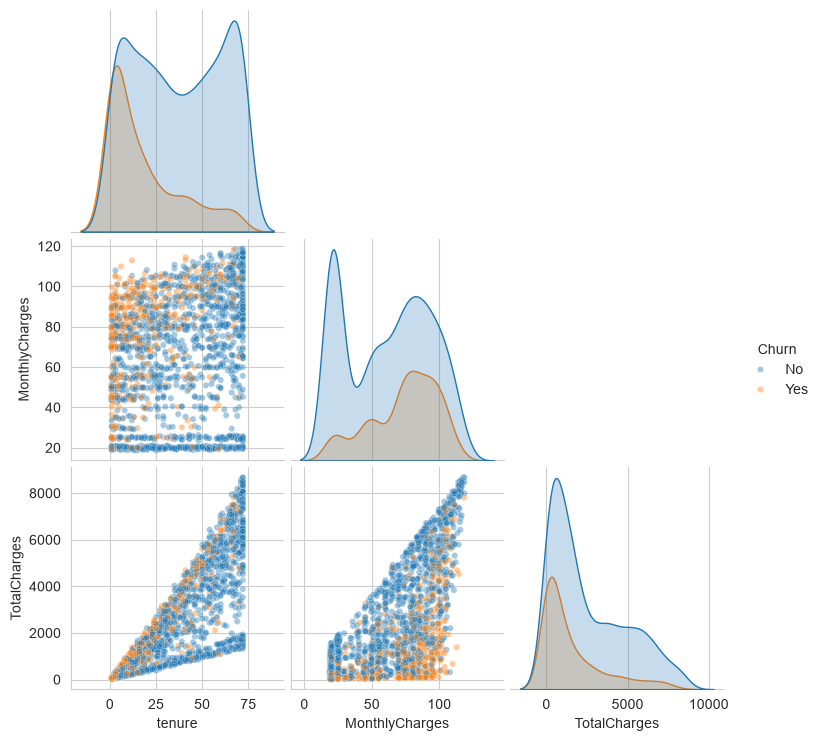

In [7]:
sample = df_eda[num_cols + ["Churn"]].dropna().sample(2000, random_state=42)

sns.pairplot(sample, hue="Churn", corner=True, plot_kws={"alpha": 0.4, "s": 20})
plt.show()

**What the code does:** It takes a random sample of 2000 customers and draws a pair plot of the three numerical features, colored by Churn. With corner=True only the lower half is drawn, because the upper half would repeat the same information.

**Why this method was used:** A pair plot shows all pairs of numerical features and their distributions together. I used a sample of 2000 rows because plotting all rows is slow and does not change the picture.

**What the output means:** On the diagonal the tenure distribution of churned customers is concentrated at low values and the not churned group is spread out with a peak at high tenure. In the scatter plots, the churned points are packed at the lower left of tenure vs TotalCharges and spread toward the higher MonthlyCharges values. The two classes overlap in every plot, and no plot separates them cleanly.

**Insights:** There is a visible tendency but no clean boundary, so churn cannot be predicted from the three numerical features alone. The categorical features add much of the information. The fan shape between tenure and TotalCharges is again visible.

**Effect on the ML pipeline:** Since the classes overlap, an accuracy near perfect should not be expected from numerical features only, and a model needs the categorical features as well. The overlap also hints that simple linear boundaries will not be enough.

## 5. Potential Multicollinearity

**Concept:** Multicollinearity happens when two or more input features are strongly correlated with each other, so they carry almost the same information. In linear and logistic regression, it makes the coefficients unstable and hard to interpret. A common rule is that a pair with an absolute correlation above about 0.8 is a concern. The variance inflation factor (VIF) is another measure, where a value above 5 or 10 is usually seen as a problem.

**Example (numerical):** A model uses both height in centimeters and height in inches as features. They are perfectly correlated, so the model cannot decide how to split the weight between them, and the coefficients become meaningless even though the predictions may still be fine.

In [8]:
corr_full = df_enc.corr()
upper = corr_full.where(np.triu(np.ones(corr_full.shape), k=1).astype(bool)).stack()
strong_pairs = upper[upper.abs() > 0.7].sort_values(key=lambda s: s.abs(), ascending=False)

print("Number of pairs with absolute correlation above 0.7:", len(strong_pairs))
print()
print(strong_pairs.head(30).round(2).to_string())

Number of pairs with absolute correlation above 0.7: 32

PhoneService                          MultipleLines_No phone service         -1.00
InternetService_No                    DeviceProtection_No internet service    1.00
                                      TechSupport_No internet service         1.00
                                      StreamingTV_No internet service         1.00
                                      OnlineBackup_No internet service        1.00
                                      OnlineSecurity_No internet service      1.00
OnlineBackup_No internet service      StreamingMovies_No internet service     1.00
                                      StreamingTV_No internet service         1.00
                                      TechSupport_No internet service         1.00
                                      DeviceProtection_No internet service    1.00
OnlineSecurity_No internet service    StreamingMovies_No internet service     1.00
                              

In [9]:
# variance inflation factor for the three numerical features (calculated with numpy)
def vif_table(data):
    result = {}
    for col in data.columns:
        y = data[col].values
        X = np.column_stack([np.ones(len(data)), data.drop(columns=col).values])
        beta = np.linalg.lstsq(X, y, rcond=None)[0]
        residual = y - X @ beta
        r2 = 1 - residual.var() / y.var()
        result[col] = 1 / (1 - r2)
    return pd.Series(result)

print(vif_table(df_eda[num_cols].dropna()).round(2))

tenure            5.84
MonthlyCharges    3.23
TotalCharges      9.53
dtype: float64


**What the code does:** The first cell takes the upper half of the correlation matrix (so every pair is counted once), keeps the pairs with an absolute correlation above 0.7 and lists the strongest thirty. The second cell calculates the VIF of each numerical feature by regressing it on the other numerical features.

**Why this method was used:** The pair list finds which features duplicate each other across all the encoded columns, and the VIF shows how much each numerical feature is explained by the others.

**What the output means:** The list contains pairs with a correlation of exactly 1.0 or -1.0. These are the No internet service columns of the six add-on services, which are identical to InternetService_No, and the PhoneService column against the No phone service column of MultipleLines. Tenure and TotalCharges (about 0.83), and MonthlyCharges and fiber optic internet (about 0.79), also appear. In the VIF table TotalCharges has the highest value, and tenure and MonthlyCharges are lower.

**Insights:** The perfect pairs come from how one-hot encoding works. Columns that all mean no internet carry exactly the same information, so only one of them is needed. TotalCharges is the main multicollinearity problem among the numerical features. Having all categories of a one-hot encoded column also creates perfect redundancy, because the last category can be worked out from the others.

**Effect on the ML pipeline:** For linear or logistic regression I should drop one dummy column per feature (drop_first), merge the repeated No internet service labels, and decide whether to remove TotalCharges or combine it with other features. Tree based models are not harmed in their predictions by multicollinearity, but their feature importance values get split between the related features.

## 6. Feature Interactions

**Concept:** An interaction means that the effect of one feature on the target depends on the value of another feature. A simple way to find it is to calculate the target rate for every combination of two categorical features. If the effect of feature A is the same in every group of B, there is no interaction, and if it changes a lot, there is one.

**Example (business):** A discount may increase sales for new customers but have no effect on loyal customers. The effect of the discount depends on the customer type, so looking at the discount alone would hide it.

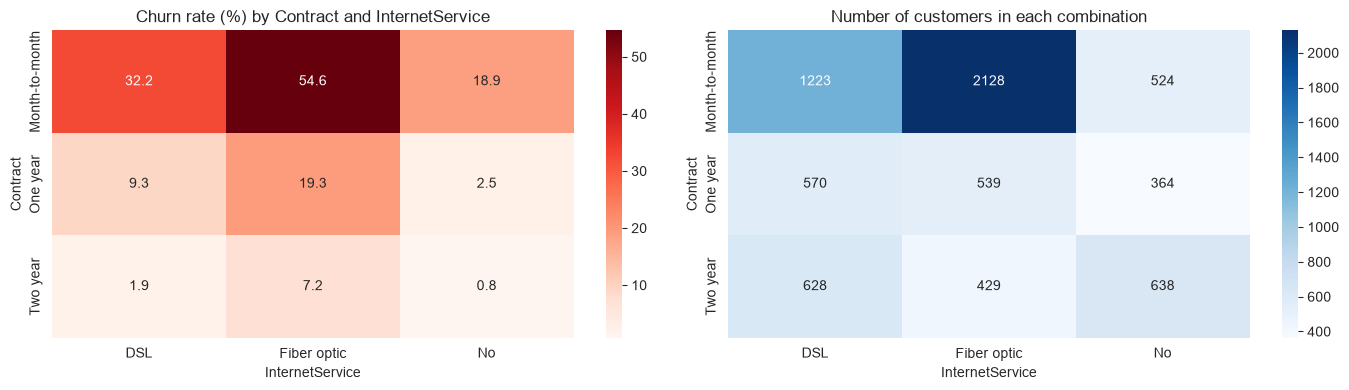

In [10]:
# churn rate (%) for each combination of Contract and InternetService
rate_table = df_eda.pivot_table(index="Contract", columns="InternetService", values="Churn_num", aggfunc="mean") * 100
count_table = df_eda.pivot_table(index="Contract", columns="InternetService", values="Churn_num", aggfunc="count")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(rate_table, annot=True, fmt=".1f", cmap="Reds", ax=axes[0])
axes[0].set_title("Churn rate (%) by Contract and InternetService")
sns.heatmap(count_table, annot=True, fmt=".0f", cmap="Blues", ax=axes[1])
axes[1].set_title("Number of customers in each combination")
plt.tight_layout()
plt.show()

In [11]:
# tenure bands and contract
df_eda["tenure_band"] = pd.cut(df_eda["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])

rate_table2 = df_eda.pivot_table(index="tenure_band", columns="Contract", values="Churn_num", aggfunc="mean", observed=True) * 100
count_table2 = df_eda.pivot_table(index="tenure_band", columns="Contract", values="Churn_num", aggfunc="count", observed=True)

print("Churn rate (%):")
print(rate_table2.round(1))
print()
print("Number of customers:")
print(count_table2)

Churn rate (%):
Contract     Month-to-month  One year  Two year
tenure_band                                    
0-12                   51.4      10.5       0.0
13-24                  37.7       8.1       0.0
25-48                  32.9      10.6       2.2
49-72                  26.0      12.9       3.3

Number of customers:
Contract     Month-to-month  One year  Two year
tenure_band                                    
0-12                   1994       124        68
13-24                   737       197        90
25-48                   802       518       274
49-72                   342       634      1263


**What the code does:** The first cell builds two tables for every combination of Contract and InternetService, one with the churn rate and one with the number of customers, and draws them as heatmaps. The second cell groups tenure into four bands and builds the same pair of tables for tenure band and Contract.

**Why this method was used:** A pivot table with heatmap is a simple way to see an interaction between two categorical features. Showing the customer counts next to the rates is important, because a high rate in a very small group is not reliable.

**What the output means:** Month-to-month customers with fiber optic internet have the highest churn rate, above 50%. Two year customers have a low churn rate in every internet service type. Churn falls with tenure in every contract type, and the 0 to 12 month band has the highest churn overall, at about 48%.

**Insights:** The fiber optic effect is not the same everywhere: it is very strong for month-to-month customers and almost disappears for two year customers, so contract and internet service interact. This also shows a priority segment: new month-to-month fiber customers. Some combinations, such as two year contracts in the first 12 months, have very few customers in the count table, so their rates should not be trusted.

**Effect on the ML pipeline:** Because of these interactions, a model that can learn interactions, like decision trees, random forests or gradient boosting, is likely to work better than a plain linear model. For a linear model, interaction features such as Contract multiplied by InternetService could be created in feature engineering.

## 7. Numerical Feature Relationships

**Concept:** Sometimes a feature is almost an exact function of other features. Checking whether one numerical column can be computed from the others shows if it adds any new information.

**Example (AI/ML):** In a sales table, Total = Quantity multiplied by Price. If the Total column is always exactly this product, the Total column has no new information and it is a redundant feature.

In [12]:
check = df_eda[["tenure", "MonthlyCharges", "TotalCharges"]].dropna().copy()
check["expected_total"] = check["tenure"] * check["MonthlyCharges"]
check["difference"] = check["TotalCharges"] - check["expected_total"]
check["difference_percent"] = (check["difference"] / check["TotalCharges"] * 100)

print("Correlation of TotalCharges with tenure x MonthlyCharges:", round(check["TotalCharges"].corr(check["expected_total"]), 4))
print()
print(check["difference_percent"].describe().round(2))

Correlation of TotalCharges with tenure x MonthlyCharges: 0.9996

count    7032.00
mean       -0.23
std         5.13
min       -45.06
25%        -2.09
50%         0.00
75%         1.92
max        36.45
Name: difference_percent, dtype: float64


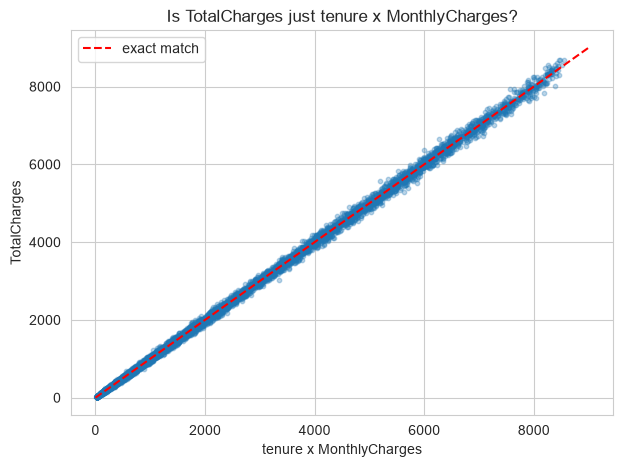

In [13]:
plt.figure(figsize=(7, 5))
plt.scatter(check["expected_total"], check["TotalCharges"], alpha=0.3, s=10)
plt.plot([0, 9000], [0, 9000], color="red", linestyle="--", label="exact match")
plt.xlabel("tenure x MonthlyCharges")
plt.ylabel("TotalCharges")
plt.title("Is TotalCharges just tenure x MonthlyCharges?")
plt.legend()
plt.show()

**What the code does:** It multiplies tenure by MonthlyCharges to get an expected total, compares it with the real TotalCharges, and prints the correlation and the percentage difference. The scatter plot puts the expected total on the x axis and the real total on the y axis, with a red line where they would be equal.

**Why this method was used:** The fan shape in the earlier scatter plot suggested that TotalCharges comes from tenure and MonthlyCharges. This test checks it directly.

**What the output means:** The correlation between TotalCharges and tenure multiplied by MonthlyCharges is very close to 1, and the points lie close to the red line. The percentage differences are small for most customers, and there are some customers with larger differences.

**Insights:** TotalCharges is mostly a product of the other two features, so it adds little independent information. The customers with a difference are probably those whose monthly price changed over time, for example because they changed plans, and that is real information the product does not capture.

**Effect on the ML pipeline:** TotalCharges is a redundant feature for the model and is the main reason for the multicollinearity seen earlier. Options for later are to drop it, or to keep it and use a tree based model, or to replace it with a feature that captures the difference, such as the change in price over time.

# Findings

| Question | Finding |
|---|---|
| Strong correlations | tenure and TotalCharges (about 0.83), MonthlyCharges and fiber optic (about 0.79), and perfect correlations between the No internet service columns |
| Moderate correlations | MonthlyCharges and TotalCharges (about 0.65), tenure and two year contract |
| Weak correlations | tenure and MonthlyCharges (about 0.25), gender and phone service with Churn (near 0) |
| Negative correlations with Churn | tenure (about -0.35), two year contract (about -0.30), no internet service (about -0.23) |
| Positive correlations with Churn | month-to-month contract, no online security, no tech support, fiber optic, electronic check (all about 0.30 to 0.40) |
| Potential multicollinearity | TotalCharges with tenure and MonthlyCharges, repeated No internet service columns, one-hot dummies |
| Interesting relationships | Fiber optic customers on month-to-month contracts churn above 50%, and tenure of 0 to 12 months has the highest churn |
| Redundant feature | TotalCharges is almost tenure multiplied by MonthlyCharges |

# Summary

- No single feature has a correlation with Churn above about 0.4, so churn depends on a combination of features.
- The strongest drivers are the contract type, tenure, internet service type, support services and payment method.
- The numerical classes overlap in the pair plot, so categorical features are needed for a good model.
- Contract and internet service interact, so models that capture interactions are likely to do better.
- Multicollinearity exists between TotalCharges, tenure and MonthlyCharges, and between the repeated No internet service dummy columns.

**Points for later sprints**
1. Decide how to treat TotalCharges (drop, keep for tree models, or replace with a derived feature).
2. Merge the No internet service and No phone service labels, or drop one dummy per feature, to avoid perfect redundancy.
3. Consider interaction features and tenure bands.
4. Test weak features such as gender before removing them.
5. Remember that correlation is not causation, so these relationships need business checking.

**What I learned:** Looking at pairs is not enough, because features interact and the effect of one feature can depend on another. I also learned that one-hot encoding by itself creates perfect correlations between columns, and that a column like TotalCharges can be almost fully explained by two other columns.

Next: `07_Outlier_Analysis.ipynb`